# §1 Problem and governance (Stages S1–S2)

This section states what is asked, of whom, and under which rules. It fixes the use case, the training target, the two evaluation populations, the feature-availability rule, the research questions with their hypotheses, and the governance obligations that come with the data. The text of the scope lives in `governance/S1_scope.md` and `governance/hypotheses.md`; this notebook renders those documents and **recomputes every number they contain** from the raw files, so a statement can never drift away from the data.

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import labels as L, survey as S

pd.set_option("display.width", 150, "display.max_colwidth", 80, "display.max_rows", 80)
GOV = C.GOVERNANCE_DIR
SCOPE_MD = (GOV / "S1_scope.md").read_text(encoding="utf-8")
HYP_MD = (GOV / "hypotheses.md").read_text(encoding="utf-8")


def md_section(text, heading):
    """Body of the markdown section whose heading line contains `heading` (until the next heading of the same or higher level)."""
    lines = text.splitlines()
    start = next(i for i, l in enumerate(lines) if re.match(r"#+\s", l) and heading.lower() in l.lower())
    level = len(re.match(r"#+", lines[start]).group())
    body = []
    for l in lines[start + 1:]:
        m = re.match(r"(#+)\s", l)
        if m and len(m.group(1)) <= level:
            break
        body.append(l)
    return "\n".join(body).strip()


def md_table(text, heading=None):
    """First pipe table (after `heading` if given) as a DataFrame of strings."""
    body = md_section(text, heading) if heading else text
    rows = [l for l in body.splitlines() if l.strip().startswith("|")]
    cells = [[c.strip() for c in r.strip().strip("|").split("|")] for r in rows]
    header, data = cells[0], [c for c in cells[2:] if len(c) == len(cells[0])]
    return pd.DataFrame(data, columns=header)

## Analysis cohort

**Why.** Every count below must come from the same cohort that later sections model. The shared loader `nhanes_io.build_cohort()` builds it: adults aged 20 or older, examined, HbA1c observed, not pregnant. The funnel is asserted step by step.

In [2]:
from src import nhanes_io

cohort = nhanes_io.build_cohort()
funnel = nhanes_io.funnel()
display(funnel)
assert len(cohort) == 5730
assert funnel["n"].tolist() == [11933, 7809, 6064, 5767, 5730]

,step,n,dropped
0,DEMO_L participants,11933,0
1,Age >= 20,7809,4124
2,Interviewed and MEC-examined (RIDSTATR = 2),6064,1745
3,HbA1c measured (LBXGH present),5767,297
4,Not pregnant (RIDEXPRG != 1),5730,37


**So what.** The cohort has 5,730 adults, reached through the funnel 11,933 → 7,809 → 6,064 → 5,767 → 5,730 that the process document fixes. Everything that follows is computed on these rows.

## Research question and use case

**Why.** A model's result is only interpretable relative to the decision it would support. The question is therefore tied to one use case.

> *Can adult diabetes (diagnosed or undiagnosed) be identified from non-glycaemic information available at a clinical contact; how much of that ability survives in the population screening is meant for; and how do data-preparation decisions change the answer?*

The use case is a **screening aid applied before any glucose test**. Models are deliberately basic (L2 logistic regression with splines; a depth-3 decision tree for thresholds and leakage probing): the model is a measuring instrument for the data, not the product. Out of scope: complex or LLM-based models, causal estimation, linkage with external individual-level data (forbidden by the data user agreement), pooling cycles, and firm conclusions about small subgroups.

## Feature-availability rule

**Why.** "Leakage" is easy to assert and hard to defend variable by variable. One rule decides all cases: a feature is admissible only if it can be obtained **at the screening moment** by questionnaire, basic physical measurement or (Tier 2) a lipid panel from the same visit, **and** it is not a diagnostic criterion, not a consequence of diagnosis, and not derived from the target. Applied to the data, the rule also exposes a quieter problem: BPQ020 and BPQ080 ("told you have high blood pressure / cholesterol") are legitimate questionnaire items but are traces of earlier contact with health care, as DIQ160 and DIQ180 are. They stay admissible and get their own ablation arm (T1-minus-care).

The table is read from `governance/S1_scope.md` and compared with `config/variable_spec.csv`, which is built from the CDC codebooks; the two must agree on every shared variable.

In [3]:
rule = md_table(SCOPE_MD, "Variable availability")
rule["tier"] = rule["admissible"]
display(rule.drop(columns="tier"))

# Hard requirements of the rule (process doc S1 step 3)
MUST_BE_N = ["LBXGH", "LBXGLU", "DIQ010", "DIQ050", "DIQ070", "DID040", "DID060", "DIQ160", "DIQ180"]
MUST_BE_T1 = ["RIDAGEYR", "RIAGENDR", "BMXBMI", "BMXWAIST", "whtr", "bp_sys_mean", "bp_dia_mean", "BPQ020", "BPQ080", "SMQ020"]
MUST_BE_T2 = ["LBXTC", "LBDHDD"]
adm = rule.set_index("variable")["admissible"]
assert all(adm[v] == "N" for v in MUST_BE_N), "leakage variable marked admissible"
assert all(adm[v] == "T1" for v in MUST_BE_T1)
assert all(adm[v] == "T2" for v in MUST_BE_T2)
assert all(rule["reason"].str.len() > 0), "every variable needs a reason"

counts = rule["admissible"].value_counts().reindex(["N", "T1", "T2"]).rename("variables")
display(counts.to_frame())
assert counts.tolist() == [14, 13, 2], counts.tolist()

# Cross-check with the variable specification.
spec = pd.read_csv(C.VARIABLE_SPEC)
spec_adm = spec.set_index("var")["admissible"].astype(str)
shared = [v for v in rule["variable"] if v in spec_adm.index]
diff = [(v, adm[v], spec_adm[v]) for v in shared if adm[v] != spec_adm[v]]
print(f"variable_spec.csv: {len(spec)} variables; {len(shared)} shared with the rule table; disagreements: {diff if diff else 'none'}")
assert not diff
SPEC_STATUS = {"n_spec": len(spec), "n_shared": len(shared), "disagreements": len(diff)}
display(pd.crosstab(spec["role"], spec["admissible"]).rename_axis(index="role (spec)", columns="admissible"))
leak = spec[spec["role"] == "leak"][["var", "file", "admiss_reason"]]
display(leak)
assert (spec.loc[spec["role"].isin(["leak", "label"]), "admissible"] == "N").all(), "leak or label variable admitted"
assert set(spec.loc[spec["role"] == "audit", "var"]) == {"RIDRETH3", "HIQ011", "HUQ030"}
care = spec[(spec["admissible"] != "N") & spec["admiss_reason"].astype(str).str.contains("care-contact")]["var"].tolist()
print("admissible but flagged as care-contact traces (T1-minus-care arm):", care)
assert set(care) == {"BPQ020", "BPQ080"}

,variable,file,meaning,admissible,reason
0,LBXGH,GHB_L,HbA1c,N,part of the target (diagnostic criterion)
1,LBXGLU,GLU_L,fasting plasma glucose,N,diagnostic criterion; fasting subsample only
2,DIQ010,DIQ_L,doctor-diagnosed diabetes,N,part of the target
3,DIQ050,DIQ_L,taking insulin,N,consequence of diagnosis
4,DIQ070,DIQ_L,taking diabetic pills,N,consequence of diagnosis; also asked of undiagnosed respondents
5,DID040,DIQ_L,age at diagnosis,N,consequence of diagnosis
6,DID060,DIQ_L,duration of insulin use,N,consequence of diagnosis
7,DIQ160,DIQ_L,told prediabetes,N,consequence of a glucose test; care-contact trace
8,DIQ180,DIQ_L,blood sugar tested in past 3 years,N,consequence of care contact
9,LBXTLG,TRIGLY_L,triglycerides,N,fasting subsample only; side analysis


,variables
admissible,
N,14
T1,13
T2,2


variable_spec.csv: 175 variables; 26 shared with the rule table; disagreements: none


admissible,N,T1,T2
role (spec),,,
audit,3,0,0
cohort_filter,2,0,0
design,2,0,0
excluded,97,0,0
feature,0,30,2
id,16,0,0
label,2,0,0
leak,8,0,0
optional,5,0,0


,var,file,admiss_reason
32,LBXGLU,GLU_L,diagnostic criterion (fasting plasma glucose >= 126 mg/dL)
88,DID040,DIQ_L,consequence of diagnosis (age at diagnosis)
89,DIQ160,DIQ_L,result of a prior glycaemic test (told prediabetes)
90,DIQ180,DIQ_L,prior blood-glucose testing in last 3 years: care-contact trace of glycaemic...
91,DIQ050,DIQ_L,treatment = consequence of diagnosis (insulin)
92,DID060,DIQ_L,consequence of diagnosis (insulin duration)
93,DIQ060U,DIQ_L,consequence of diagnosis (unit of DID060)
94,DIQ070,DIQ_L,treatment = consequence of diagnosis or prediabetes (oral medication)


admissible but flagged as care-contact traces (T1-minus-care arm): ['BPQ020', 'BPQ080']


**So what.** The rule rejects 14 variables: nine glycaemic or diagnosis-related ones (HbA1c, fasting glucose, the diagnosis item itself, insulin and pill use, age at diagnosis, insulin duration, "told prediabetes", "glucose tested in the past three years"), two fasting-subsample lipids (triglycerides, LDL), and race, insurance and usual place of care, which are kept as audit variables only. It admits 13 Tier-1 inputs and 2 Tier-2 lipids. The variable specification built from the codebooks (Stage S2) agrees with this table on every shared variable; it marks eight further variables with role `leak` (the diagnosis consequences and the fasting glucose) and flags exactly BPQ020 and BPQ080 as care-contact traces. Because the decision is made by rule and not per variable, any later reviewer can re-derive it.

## Evaluation populations

**Why.** The frozen target is `L_comb` = self-reported physician diagnosis **or** HbA1c ≥ 6.5 %. If most positives were already diagnosed, a high AUC would mostly mean "recognises people who have a diagnosis and the health-care footprint that comes with it", which is not screening value. The composition of the positive class is therefore computed before any model is fitted, and two populations are made co-primary:

- **E-ALL**: the whole cohort, label `L_comb`.
- **E-SCREEN**: people without a reported diagnosis (DIQ010 ≠ 1); positive = HbA1c ≥ 6.5 %.

In [4]:
c = L.add_labels(cohort)

n = len(c)
n_self, n_a1c, n_comb = int(c["L_self"].sum()), int(c["L_A1c"].sum()), int(c["L_comb"].sum())
n_escr = int(c["in_escreen"].sum())
n_escr_pos = int(((c["in_escreen"] == 1) & (c["L_A1c"] == 1)).sum())
n_escr_neg = n_escr - n_escr_pos
share_known = n_self / n_comb
strata = c["stratum_3x3"].value_counts().reindex(L.STRATA_3X3).astype(int)

pop = pd.DataFrame([
    ["E-ALL", n, n_comb, n - n_comb, "L_comb"],
    ["E-SCREEN", n_escr, n_escr_pos, n_escr_neg, "HbA1c >= 6.5 among DIQ010 != 1"],
], columns=["population", "rows", "positives", "negatives", "positive class"])
display(pop)
print(f"L_self {n_self}, L_A1c {n_a1c}, L_comb {n_comb}; already self-reported share of L_comb = {share_known:.1%}")
display(strata.rename("rows").to_frame())

prev_u = n_comb / n
prev_w = S.weighted_prop(c, "L_comb", weight=C.WEIGHT_PHLEB)
print(f"prevalence of L_comb: unweighted {prev_u:.1%}; WTPH2YR-weighted {prev_w['est']:.1%} "
      f"(95% CI {prev_w['ci_low']:.1%} to {prev_w['ci_high']:.1%}, df {prev_w['df']})")

assert (n_self, n_a1c, n_comb) == (819, 721, 971)
assert (n_escr_pos, n_escr_neg) == (152, 4759)
assert strata.tolist() == [569, 250, 152, 4759]
assert abs(share_known - 0.843) < 0.001
assert abs(prev_u - 0.169) < 0.001 and abs(prev_w["est"] - 0.140) < 0.001

,population,rows,positives,negatives,positive class
0,E-ALL,5730,971,4759,L_comb
1,E-SCREEN,4911,152,4759,HbA1c >= 6.5 among DIQ010 != 1


L_self 819, L_A1c 721, L_comb 971; already self-reported share of L_comb = 84.3%


,rows
stratum_3x3,
D_uncontrolled,569
D_controlled,250
Undiagnosed,152
NonDiabetic,4759


prevalence of L_comb: unweighted 16.9%; WTPH2YR-weighted 14.0% (95% CI 12.4% to 15.6%, df 15)


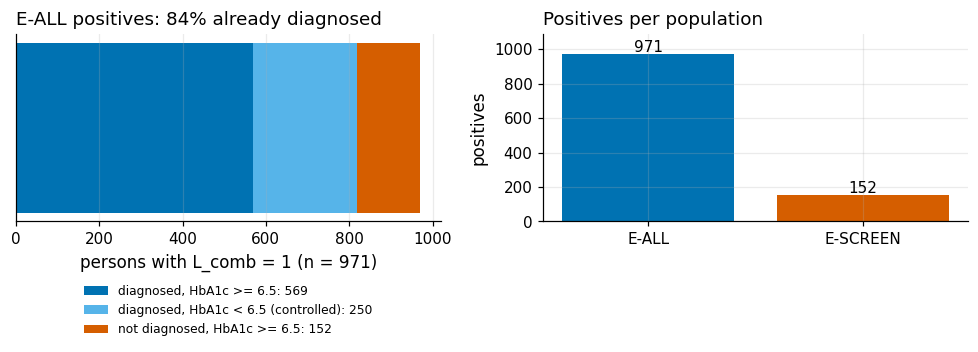

saved figures/S1_label_composition.png


In [5]:
plots.set_style()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), gridspec_kw={"width_ratios": [1, 1]})
ok = C.OKABE_ITO
# Panel 1: who the 971 positives are
ax = axes[0]
parts = [("diagnosed, HbA1c >= 6.5", strata["D_uncontrolled"], ok["blue"]),
         ("diagnosed, HbA1c < 6.5 (controlled)", strata["D_controlled"], ok["sky"]),
         ("not diagnosed, HbA1c >= 6.5", strata["Undiagnosed"], ok["vermillion"])]
left = 0
for lab, v, col in parts:
    ax.barh(0, v, left=left, color=col, label=f"{lab}: {v}")
    left += v
ax.set_yticks([]); ax.set_xlabel(f"persons with L_comb = 1 (n = {n_comb})")
ax.set_title(f"E-ALL positives: {share_known:.0%} already diagnosed", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), fontsize=8)
# Panel 2: E-SCREEN
ax = axes[1]
ax.bar(["E-ALL", "E-SCREEN"], [n_comb, n_escr_pos], color=[ok["blue"], ok["vermillion"]])
for i, v in enumerate([n_comb, n_escr_pos]):
    ax.text(i, v + 15, str(v), ha="center")
ax.set_ylabel("positives"); ax.set_ylim(0, n_comb * 1.12); ax.set_title("Positives per population", loc="left")
fig.tight_layout()
f_comp = plots.savefig(fig, "S1_label_composition",
                       caption=f"Composition of the {n_comb} L_comb positives. {n_self} ({share_known:.1%}) already reported a diagnosis; "
                               f"only {n_escr_pos} are undiagnosed with HbA1c >= 6.5 and form the E-SCREEN positive class.")
plt.show(); print("saved", f_comp)

**So what.** Of the 971 positives, 819 (84.3 %) had already reported a diagnosis; only 152 are undiagnosed. E-ALL therefore rewards recognising known patients, while E-SCREEN (152 positives against 4,759 negatives) is the population in which a screening aid has something to find. Weighting matters for prevalence: 16.9 % unweighted against 14.0 % with the examination-blood weights, mainly because older adults are over-represented in the sample. The gap between model performance on E-ALL and on E-SCREEN is reported as a finding in its own right, not as noise. With only 152 positives, many E-SCREEN contrasts will be *inconclusive*; that is stated in advance.

## Research questions and hypotheses

**Why.** Four questions organise the whole project, and each hypothesis has a metric, a direction, a magnitude, a smallest effect of interest (SESOI), a falsifier and an honest record of whether the data had been seen. The hypotheses are read from `governance/hypotheses.md`, which Stage S6 locks with a SHA-256 before any ablation is run.

| RQ | Question |
|---|---|
| RQ1 | **Labels as measurement.** What do self-report and HbA1c each measure, and who is missed by each? |
| RQ2 | **Rules and preparation.** How much do the availability rule (leakage) and systematic preparation change performance and stability, on E-ALL and on E-SCREEN? |
| RQ3 | **3 × 3 label matrix.** How does the training label change who is detected? |
| RQ4 | **Measurement bias.** Does BMI under-detect diabetes in Asian adults, and does waist-to-height ratio repair it? |

In [6]:
hyp = md_table(HYP_MD, "Hypothesis table")
display(hyp[["hyp_id", "rq_or_block", "statement", "prior_exposure"]])

ALLOWED_EXPOSURE = {"analysis_seen", "descriptive_seen", "none"}
FIELDS = ["metric", "direction", "magnitude", "sesoi", "falsifier", "prior_exposure", "weights"]
assert hyp["hyp_id"].tolist() == ["H1a", "H1b", "H2a", "H2b", "H2c", "H3", "H4a", "H4b"]
assert set(hyp["prior_exposure"]) <= ALLOWED_EXPOSURE
assert (hyp[FIELDS].apply(lambda col: col.str.len() > 0)).all().all(), "every hypothesis needs all fields"
expo = hyp["prior_exposure"].value_counts().reindex(sorted(ALLOWED_EXPOSURE)).fillna(0).astype(int)
display(expo.rename("hypotheses").to_frame())
rq_map = hyp.assign(rq=hyp["rq_or_block"].str.extract(r"(RQ\d)")[0]).groupby("rq")["hyp_id"].apply(list)
display(rq_map.rename("hypotheses").to_frame())

,hyp_id,rq_or_block,statement,prior_exposure
0,H1a,RQ1 (S5),"Among adults with HbA1c of 6.5 or more, the share not yet diagnosed (DIQ010 ...",analysis_seen
1,H1b,RQ1 (S4),The crude insured-minus-uninsured gap in diabetes prevalence shrinks after a...,analysis_seen
2,H2a,RQ2 / B1 (S7),A model that breaks the availability rule (M0) beats the same model with the...,analysis_seen
3,H2b,RQ2 / M1 vs S (S7),Systematic preparation (S) is equivalent to the availability-screened minima...,none
4,H2c,RQ2 / E-ALL vs E-SCREEN (S7),(i) T1 discriminates better on E-ALL than on E-SCREEN; (ii) removing the car...,none
5,H3,RQ3 (S8),In the 3 x 3 label matrix the training label determines who is missed: self-...,none
6,H4a,RQ4 (S5),"Among adults with diabetes, the share with BMI below 25 is much higher in As...",analysis_seen
7,H4b,"RQ4 (S5, S8)",Replacing waist circumference by waist-to-height ratio improves single-featu...,descriptive_seen


,hypotheses
prior_exposure,
analysis_seen,4
descriptive_seen,1
none,3


,hypotheses
rq,
RQ1,"[H1a, H1b]"
RQ2,"[H2a, H2b, H2c]"
RQ3,[H3]
RQ4,"[H4a, H4b]"


**So what.** Eight hypotheses cover the four questions (H1a, H1b → RQ1; H2a–H2c → RQ2; H3 → RQ3; H4a, H4b → RQ4) and every one carries all seven fields. Honesty about exposure matters more than the label: four hypotheses are `analysis_seen` (the pattern was observed in the earlier profiling), one is `descriptive_seen`, and only the three experimental ones (H2b, H2c, H3) are genuine pre-registrations. Stages S3–S5 are described as confirmation of observed patterns, never as pre-registered tests.

## ADA-lite baseline

**Why.** A published risk score is the natural yardstick for a simple model, but this cycle lacks two of the seven items of Bang et al. 2009 (family history of diabetes, gestational diabetes). Calling the result "the ADA score" would overstate it. The baseline is therefore **ADA-lite, a reduced version missing 2 items**, compared on E-SCREEN only, because Bang's outcome is undiagnosed diabetes. The absence of the two items is checked in the CDC codebooks, not assumed.

In [7]:
ada = md_table(SCOPE_MD, "ADA-lite baseline")
display(ada)
n_avail = int((ada["Status"] == "available").sum())
n_miss = int(ada["Status"].str.contains("missing").sum())
print(f"ADA-lite items available: {n_avail} of {len(ada)}; missing: {n_miss}")
assert (n_avail, n_miss) == (5, 2)


def codebook_text(stem):
    t = (C.CODEBOOK_DIR / f"{stem}.htm").read_text(encoding="utf-8", errors="ignore")
    return re.sub(r"\s+", " ", re.sub(r"<[^>]+>", " ", t)).lower()


evidence = []
for stem in ["MCQ_L", "DIQ_L"]:
    t = codebook_text(stem)
    for term in ["family history", "blood relative", "gestational"]:
        evidence.append({"codebook": stem, "search term": term, "hits": t.count(term)})
    # 'during pregnancy' occurs in the wording of DIQ010 ("Other than during pregnancy ...") and is not a gestational-diabetes item
    evidence.append({"codebook": stem, "search term": "during pregnancy", "hits": t.count("during pregnancy")})
ev = pd.DataFrame(evidence)
display(ev)
ctx = [codebook_text("DIQ_L")[max(0, m.start() - 60): m.end() + 80] for m in re.finditer("during pregnancy", codebook_text("DIQ_L"))]
print("context of 'during pregnancy' in DIQ_L:", ctx[:2])
assert ev.query("`search term` in ['family history','blood relative','gestational']")["hits"].sum() == 0

,Item (Bang 2009),NHANES 2021-23,Status
0,Age,RIDAGEYR,available
1,Sex,RIAGENDR,available
2,History of hypertension,BPQ020,available
3,Body mass index,BMXBMI (measured),available
4,Physical activity,PAQ recreational items converted to minutes per week; >= 150 minutes counts ...,available
5,Family history of diabetes,none in MCQ_L or DIQ_L,**missing**
6,Gestational diabetes,none in the 2021-23 files,**missing**


ADA-lite items available: 5 of 7; missing: 2


,codebook,search term,hits
0,MCQ_L,family history,0
1,MCQ_L,blood relative,0
2,MCQ_L,gestational,0
3,MCQ_L,during pregnancy,0
4,DIQ_L,family history,0
5,DIQ_L,blood relative,0
6,DIQ_L,gestational,0
7,DIQ_L,during pregnancy,2


context of 'during pregnancy' in DIQ_L: ['uestions are about specific medical conditions. {other than during pregnancy, {have you/has sp}/{have you/has sp}} ever been told by a doctor or health prof', 'play. if sp is female and age &gt;= 20, display "other than during pregnancy, {have you/has sp}". target: both males and females 1 years - 150 years code or']


**So what.** Five of the seven items exist (age, sex, hypertension history, measured BMI, recreational physical activity); family history and gestational diabetes do not occur in the MCQ_L or DIQ_L codebooks (zero hits for each search term). The only mention of pregnancy in DIQ_L is the exclusion wording of the diagnosis question itself. The baseline is reported under the name ADA-lite, and the open point that the published AUC of Bang 2009 is quoted as 0.79 or 0.83 in different sources is flagged for verification against the original paper.

## Novelty statement

**Why.** A contribution should be stated at the strength the evidence supports. The statement below says what is *combined*, not what is "first". It is read from `governance/S1_scope.md`, and the cell asserts that it contains no priority or superlative words.

In [8]:
novelty = md_section(SCOPE_MD, "Novelty statement")
display(Markdown("> " + novelty))
FORBIDDEN = ["first", "novel", "best", "optimal", "state-of-the-art", "unprecedented", "never before", "pioneer"]
hits = [w for w in FORBIDDEN if re.search(rf"\b{re.escape(w)}\b", novelty, flags=re.I)]
assert not hits, hits
print("novelty statement: no priority or superlative words;", len(novelty.split()), "words")

> This project does not claim to discover that Asian adults develop diabetes at lower BMI, or that undiagnosed diabetes is linked to limited contact with health care; both are established. Its contribution is a combination applied to the 2021-2023 NHANES cycle with fixed basic models: an audit of the label as a measurement, a feature-availability rule that defines leakage, the quantified cost of blanket data cleaning, design-aware evaluation, and pre-registered paired ablations, triangulated against the published NCHS Data Brief 516 and a reduced ADA risk baseline. We have not found this integration in the literature we consulted **[to verify]**.

novelty statement: no priority or superlative words; 99 words


## Data user agreement and disclosure controls

**Why.** NHANES public-use files are released under the NCHS Data User Agreement. Compliance is part of the method: it forbids some analyses (linkage with other individual-level data) and shapes others (how small groups are reported). Each obligation is mapped to what the project does.

In [9]:
dua = md_table(SCOPE_MD, "Data user agreement obligations")
display(dua)
assert len(dua) == 5

,Obligation (NCHS DUA),How the project complies
0,Use for statistical reporting and analysis only,Only population-level estimation and model evaluation; no individual-level d...
1,No attempt to identify any person or establishment,No identifying fields are used; no external lookup
2,No linkage with other data sets that could identify individuals,"External validation is against published aggregates only (DB516, Bang 2009)"
3,No study of disclosure-control methods,"Top-coding is taken as given and documented, never probed"
4,Presentation standards for survey estimates,"Flag n < 30, effective n < 30, 95 % CI width >= 0.30, domain df < 8 as explo..."


NCHS already applies disclosure controls to the public files. The project does not probe them; it makes their footprint visible so that a top-coded value is never mistaken for a measurement. The counts are computed on the cohort.

In [10]:
age_top = int((c["RIDAGEYR"] == 80).sum())
pir_top = int((c["INDFMPIR"] >= 5 - 1e-9).sum())
pir_na = int(c["INDFMPIR"].isna().sum())
# household size and pregnancy status are minimised away from the cohort; their disclosure footprint is read from the public DEMO_L file
demo_raw = pd.read_sas(C.RAW_DIR / "DEMO_L.xpt", format="xport")
hh_max = float(demo_raw["DMDHHSIZ"].max())
preg_known = demo_raw[demo_raw["RIDEXPRG"].notna()]
strata_n = int(c[C.STRATA].nunique())
psu_n = int(c.groupby(C.STRATA)[C.PSU].nunique().sum())

dc = pd.DataFrame([
    ["Age top-coded at 80 (RIDAGEYR == 80)", age_top, f"{age_top / n:.1%} of cohort", "indicator age_top"],
    ["Income-to-poverty ratio top-coded at 5 (INDFMPIR)", pir_top, f"{pir_top / n:.1%} of cohort", "indicator pir_top"],
    ["Income-to-poverty ratio missing", pir_na, f"{pir_na / n:.1%} of cohort", "indicator pir_miss"],
    ["Household size, maximum value in DEMO_L (top-coded at 7)", hh_max, "dropped by minimisation", "documented in spec note"],
    ["Pregnancy status recorded only for women aged 20-44", f"{preg_known['RIDAGEYR'].min():.0f}-{preg_known['RIDAGEYR'].max():.0f}", f"{len(preg_known)} women in DEMO_L", "pregnant women excluded by the cohort rule"],
    ["Masked variance strata / PSUs", f"{strata_n} / {psu_n}", f"design df = {psu_n - strata_n}", "delete-one-PSU jackknife"],
], columns=["control", "value", "context", "handling"])
display(dc)
assert (age_top, pir_top, pir_na) == (321, 1282, 734)
assert (strata_n, psu_n) == (15, 30) and hh_max == 7
assert preg_known["RIDAGEYR"].between(20, 44).all()

,control,value,context,handling
0,Age top-coded at 80 (RIDAGEYR == 80),321,5.6% of cohort,indicator age_top
1,Income-to-poverty ratio top-coded at 5 (INDFMPIR),1282,22.4% of cohort,indicator pir_top
2,Income-to-poverty ratio missing,734,12.8% of cohort,indicator pir_miss
3,"Household size, maximum value in DEMO_L (top-coded at 7)",7.0,dropped by minimisation,documented in spec note
4,Pregnancy status recorded only for women aged 20-44,20-44,1503 women in DEMO_L,pregnant women excluded by the cohort rule
5,Masked variance strata / PSUs,15 / 30,design df = 15,delete-one-PSU jackknife


**So what.** 321 adults (5.6 %) are top-coded at age 80 and 1,282 (22.4 %) at an income ratio of 5, with another 734 (12.8 %) missing, so the income variable is both capped and incomplete; the corresponding indicators are kept next to the values. The variance units are masked (15 strata, 30 PSUs, df = 15), which is why every design-based interval in this project uses the jackknife with these 15 degrees of freedom and why small domains are flagged. No part of the analysis tries to undo these controls or to link records to anything else; external checks use published aggregates only.

## Data minimisation

**Why.** Collecting or keeping more than the purpose needs is a governance risk even with public data (purpose limitation and data minimisation, e.g. GDPR Art. 5(1)(b)–(c); the Singapore PDPA has a purpose-limitation obligation). The loader keeps only columns that the variable specification keeps (`use_tier` other than `excluded`); `nhanes_io.minimisation_report` lists what was kept and dropped per file and per column.

In [11]:
mrep, mcols = nhanes_io.minimisation_report(spec)
display(mrep[["file", "use_tier", "cols_raw", "cols_kept", "cols_dropped"]])
tot_raw, tot_kept, tot_drop = (int(mrep[k].sum()) for k in ["cols_raw", "cols_kept", "cols_dropped"])
assert tot_raw == tot_kept + tot_drop
assert (tot_raw, tot_kept, tot_drop) == (175, 78, 97), "text of the so-what cell must be updated"
print(f"{tot_raw} raw columns in 16 files: {tot_kept} kept ({tot_kept / tot_raw:.0%}), {tot_drop} dropped ({tot_drop / tot_raw:.0%})")
examples = ["DMDBORN4", "DMDYRUSR", "DMQMILIZ", "DMDHHSIZ", "MCQ010"]
display(mcols[mcols["var"].isin(examples)][["file", "var", "decision", "reason"]])
assert (mcols["decision"] == "drop").sum() == tot_drop
MIN_STATUS = {"raw_columns": tot_raw, "kept": tot_kept, "dropped": tot_drop}

,file,use_tier,cols_raw,cols_kept,cols_dropped
0,DEMO_L,core,27,13,14
1,GHB_L,core,3,3,0
2,GLU_L,side_analysis,4,3,1
3,BMX_L,core,22,7,15
4,BPXO_L,core,12,10,2
5,TCHOL_L,core,4,2,2
6,HDL_L,core,4,2,2
7,TRIGLY_L,side_analysis,10,3,7
8,DIQ_L,core,9,9,0
9,BPQ_L,recommended,6,3,3


175 raw columns in 16 files: 78 kept (45%), 97 dropped (55%)


,file,var,decision,reason
10,DEMO_L,DMQMILIZ,drop,military service: not needed (minimisation)
11,DEMO_L,DMDBORN4,drop,country of birth: not needed; quasi-identifier (minimisation)
12,DEMO_L,DMDYRUSR,drop,years in the US: not needed; quasi-identifier (minimisation)
16,DEMO_L,DMDHHSIZ,drop,"household size (top-coded 7): not needed, PIR already accounts for household..."
102,MCQ_L,MCQ010,drop,unrelated MCQ item (minimisation)


**So what.** Of 175 raw columns in the 16 files, 78 are kept and 97 are dropped (55 %) because the specification gives them no analytic role: quasi-identifiers such as country of birth and years of residence, military service, household-size details, measurement-comment codes and unrelated MCQ items. Every dropped column has a stated reason in `minimisation_columns.csv`, and the loader discards them immediately after reading, so downstream code cannot use them by accident.

## Response rates and representativeness

**Why.** Survey weights make the sample resemble the US civilian non-institutionalised population *as far as known covariates allow*. They cannot repair non-response that depends on health. The 2021–2023 cycle has a low response and no oversampling of specific groups, which limits both generalisation and subgroup analysis.

,item,value,source
0,Interview response rate,34.6 %,NCHS cycle overview (not computable from the files)
1,Examination (MEC) response rate,25.7 %,NCHS cycle overview (not computable from the files)
2,Oversampling by race/ethnicity or income,none in this cycle,NCHS cycle overview; earlier cycles oversampled


,unweighted,WTPH2YR-weighted
20-39,24.7,34.8
40-59,29.2,33.8
60+,46.2,31.4


Kish design effect of the weights: 1.55; effective sample size 3707 of 5730
Asian adults in cohort: 315, of whom 50 with L_comb


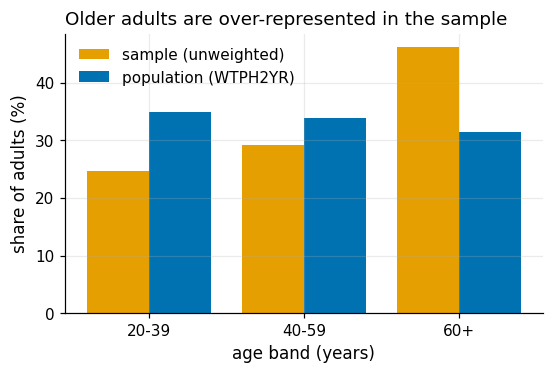

saved figures/S1_sample_vs_weighted_age.png


In [12]:
RESP = pd.DataFrame([
    ["Interview response rate", "34.6 %", "NCHS cycle overview (not computable from the files)"],
    ["Examination (MEC) response rate", "25.7 %", "NCHS cycle overview (not computable from the files)"],
    ["Oversampling by race/ethnicity or income", "none in this cycle", "NCHS cycle overview; earlier cycles oversampled"],
], columns=["item", "value", "source"])
display(RESP)

w = c[C.WEIGHT_PHLEB]
bands = S.age_band(c["RIDAGEYR"]).values
tab = pd.DataFrame({"unweighted": pd.Series(bands).value_counts(normalize=True),
                    "WTPH2YR-weighted": pd.Series(w.values).groupby(bands).sum() / w.sum()}).loc[["20-39", "40-59", "60+"]]
display((tab * 100).round(1))
deff = S.kish_deff(w)
print(f"Kish design effect of the weights: {deff:.2f}; effective sample size {S.kish_neff(w):.0f} of {n}")
n_asian = int((c['RIDRETH3'] == 6).sum())
n_asian_pos = int(((c['RIDRETH3'] == 6) & (c['L_comb'] == 1)).sum())
print(f"Asian adults in cohort: {n_asian}, of whom {n_asian_pos} with L_comb")
assert (n_asian, n_asian_pos) == (315, 50)
assert abs(tab.loc["60+", "unweighted"] - 0.462) < 0.001 and abs(tab.loc["60+", "WTPH2YR-weighted"] - 0.314) < 0.001
assert abs(deff - 1.55) < 0.01

fig, ax = plt.subplots(figsize=(5.6, 3.3))
x = np.arange(3)
ax.bar(x - 0.2, tab["unweighted"] * 100, 0.4, color=C.OKABE_ITO["orange"], label="sample (unweighted)")
ax.bar(x + 0.2, tab["WTPH2YR-weighted"] * 100, 0.4, color=C.OKABE_ITO["blue"], label="population (WTPH2YR)")
ax.set_xticks(x, tab.index); ax.set_xlabel("age band (years)"); ax.set_ylabel("share of adults (%)")
ax.set_title("Older adults are over-represented in the sample", loc="left"); ax.legend()
f_age = plots.savefig(fig, "S1_sample_vs_weighted_age",
                      caption=f"Age structure of the {n} cohort adults, unweighted versus WTPH2YR-weighted. 60+ is {tab.loc['60+','unweighted']:.1%} of the sample "
                              f"but {tab.loc['60+','WTPH2YR-weighted']:.1%} of the weighted population; Kish design effect {deff:.2f}.")
plt.show(); print("saved", f_age)

**So what.** Adults aged 60 and over are 46.2 % of the sample but 31.4 % of the weighted population, so unweighted figures overstate prevalence (16.9 % against 14.0 %); the Kish design effect of 1.55 means the 5,730 adults carry roughly the information of 3,700 simple-random-sample adults before clustering is considered. Interview (34.6 %) and examination (25.7 %) response rates are low, and the cycle has no oversampling, so subgroups such as Asian adults (315 in the cohort, 50 with `L_comb`) are thin: their results are reported with intervals and labelled exploratory. The weights adjust for known covariates only; if participation depends on health, as the interview-versus-examination comparison in Stage S5 suggests, some bias remains and is acknowledged as a limitation rather than corrected.

## Scope decisions

The decisions of this section are recorded in `governance/register/S1.csv`; the table lists them with the self-check verdict (a re-computation of the key counts above).

In [13]:
reg_path = GOV / "register" / "S1.csv"
reg = pd.read_csv(reg_path)
display(reg[["dr_id", "type", "decision", "hyp_id", "check_verdict"]])
assert reg["check_verdict"].isin(["PASS", "PASS-FIX"]).all()

payload = {
    "n_cohort": n,
    "funnel": dict(zip(funnel["step"], funnel["n"])),
    "labels": {"L_self": n_self, "L_A1c": n_a1c, "L_comb": n_comb, "known_share_of_comb": share_known},
    "e_all": {"rows": n, "positives": n_comb},
    "e_screen": {"rows": n_escr, "positives": n_escr_pos, "negatives": n_escr_neg},
    "strata_3x3": strata.to_dict(),
    "prevalence_comb": {"unweighted": prev_u, "weighted": prev_w["est"],
                        "ci_low": prev_w["ci_low"], "ci_high": prev_w["ci_high"], "df": prev_w["df"]},
    "kish_deff": deff,
    "age60_share": {"sample": float(tab.loc["60+", "unweighted"]), "weighted": float(tab.loc["60+", "WTPH2YR-weighted"])},
    "disclosure": {"age_top": age_top, "pir_top": pir_top, "pir_missing": pir_na, "strata": strata_n, "psu": psu_n},
    "availability_rule": {"n_rule_rows": len(rule), "by_tier": counts.to_dict(), "spec": SPEC_STATUS},
    "ada_lite": {"items": len(ada), "available": n_avail, "missing": n_miss},
    "hypotheses": {"n": len(hyp), "prior_exposure": expo.to_dict()},
    "minimisation": MIN_STATUS,
    "response_rates": {"interview": 0.346, "mec": 0.257, "source": "NCHS cycle overview"},
}
R.save_section("S1", payload)
(C.RESULTS_DIR / "S1").mkdir(exist_ok=True)
rule.drop(columns="tier").to_csv(C.RESULTS_DIR / "S1" / "availability_rule.csv", index=False)
pop.to_csv(C.RESULTS_DIR / "S1" / "evaluation_populations.csv", index=False)
print("saved results/metrics_S1.json; S1 OK")

,dr_id,type,decision,hyp_id,check_verdict
0,DR-S1-01,scope,Frame the question as non-glycaemic identification of adult diabetes (diagno...,RQ1-RQ4,PASS
1,DR-S1-02,target,"Freeze L_comb = DIQ010==1 or LBXGH>=6.5 on adults >=20, examined, non-pregna...",H2a,PASS
2,DR-S1-03,scope,Report E-ALL and E-SCREEN as co-primary populations; the gap between them is...,H2c,PASS
3,DR-S1-04,rule,"Admit a feature only if available at the screening moment, not a diagnostic ...",H2a,PASS
4,DR-S1-05,rule,Keep them admissible and add a T1-minus-care ablation arm reported on E-ALL ...,H2c,PASS
5,DR-S1-06,rule,Exclude from models by default; use as audit and stratification variables,H1a,PASS
6,DR-S1-07,baseline,"Use ADA-lite (reduced version, missing 2 items), compared on E-SCREEN only; ...",H2c,PASS
7,DR-S1-08,hypotheses,"Define H1a-H4b with prior_exposure markers; only H2b, H2c and H3 claim true ...",H1a-H4b,PASS
8,DR-S1-09,claims,State the contribution as a combination applied to one cycle with fixed basi...,NaN,PASS
9,DR-S1-10,governance,"Validate externally only against published aggregates (DB516, Bang 2009); ta...",NaN,PASS


saved results/metrics_S1.json; S1 OK
